In [1]:
import numpy as np
from src.models import LogisticRegression
from src.visualization import plot_cost_history

## Model Training and Evaluation

In this section, I train a Logistic Regression model from scratch using the preprocessed data. The model is implemented using only NumPy (no scikit-learn), allowing for full control over the training process and better understanding of the underlying mathematics.

### 1. Load Preprocessed Data

**Input data:**
- `train_features`: Processed training features (NumPy array)
  - All categorical features encoded to numerical values
  - All numerical features standardized (mean=0, std=1)
  - Shape: (n_samples, n_features)
- `train_target`: Binary target labels (0 or 1)
  - 0: Candidate will NOT look for a new job
  - 1: Candidate WILL look for a new job

### 2. Initialize Logistic Regression Model

**Model parameters:**
- `learning_rate=0.01`: Step size for gradient descent
- `iterations=1000`: Number of training iterations

**Why Logistic Regression?**
- **Interpretable**: Coefficients show feature importance
- **Fast**: Efficient training even on large datasets
- **Probabilistic**: Outputs probabilities (0-1) rather than hard classifications
- **Baseline model**: Good starting point before trying complex models

### 3. Training Process

**Gradient Descent optimization:**
1. Initialize weights randomly
2. For each iteration:
   - Compute predictions using sigmoid function
   - Calculate binary cross-entropy loss
   - Compute gradients of the loss with respect to weights
   - Update weights in the direction that reduces loss
3. Track cost history to monitor convergence

**Cost function visualization:**
- Plot the cost (loss) over iterations
- Should show a decreasing trend, indicating successful learning
- If cost increases or oscillates, learning rate may be too high

### 4. Model Evaluation

**Metrics used:**
- **Accuracy**: Overall correctness (TP + TN) / Total
- **Precision**: Of all predicted positives, how many are correct? TP / (TP + FP)
- **Recall**: Of all actual positives, how many did we catch? TP / (TP + FN)
- **F1-score**: Harmonic mean of Precision and Recall (balances both)

In [2]:
# Load the processed data
with np.load('../data/processed/processed_data.npz') as data:
    train_features = data['train_features']
    train_target = data['train_target']
    test_features = data['test_features']

In [3]:
# Initialize and train the model
model = LogisticRegression(learning_rate=0.01, iterations=1000)
model.fit(train_features, train_target)

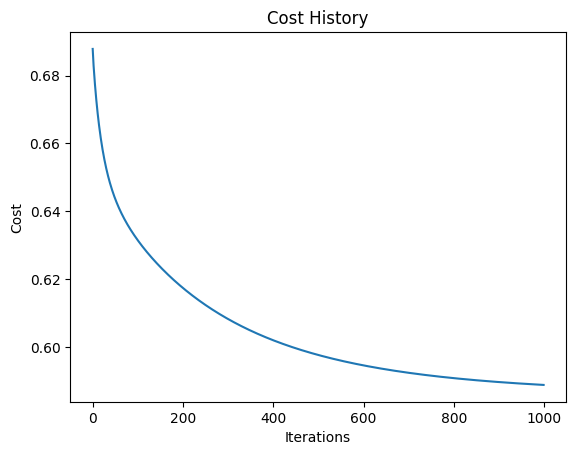

In [4]:
# Plot the cost history
plot_cost_history(model.cost_history)

In [5]:
# Evaluate the model
metrics = model.evaluate(train_features, train_target)
print(f"Accuracy: {metrics['accuracy']}")
print(f"Precision: {metrics['precision']}")
print(f"Recall: {metrics['recall']}")
print(f"F1-score: {metrics['f1_score']}")

Accuracy: 0.716035168515805
Precision: 0.7281167108753316
Recall: 0.6895541134603308
F1-score: 0.708310934308139


In [8]:
# Predictions for the test set
predictions = model.predict(test_features)
print(f"Predictions generated")
print(f"  - Total predictions: {len(predictions)}")
print(f"  - Predicted class 1 (will leave): {np.sum(predictions == 1)} ({np.mean(predictions):.2%})")
print(f"  - Predicted class 0 (will stay): {np.sum(predictions == 0)} ({1-np.mean(predictions):.2%})")

Predictions generated
  - Total predictions: 2129
  - Predicted class 1 (will leave): 776 (36.45%)
  - Predicted class 0 (will stay): 1353 (63.55%)


In [12]:
enrollee_ids = np.loadtxt('../data/raw/aug_test.csv', delimiter=',', skiprows=1, usecols=0, dtype=int)
submission_data = np.column_stack((enrollee_ids, predictions))

# Save to CSV
submission_path = 'data/processed/submission.csv'
np.savetxt(
    '../'+submission_path,
    submission_data,
    delimiter=',',
    header='enrollee_id,target',
    comments='',
    fmt='%s,%d'
)

print(f"Submission file created: {submission_path}")

Submission file created: data/processed/submission.csv
